##**Earthquake & Tsunami Prediction**

**Libraries**

In [ ]:
!pip install scikeras

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
from google.colab import drive
from sklearn.utils import resample
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest
from tensorflow.keras.models import Model
from scikeras.wrappers import KerasRegressor,KerasClassifier
from sklearn.ensemble import BaggingClassifier, BaggingRegressor
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error,r2_score, accuracy_score
from sklearn.linear_model import LinearRegression
from imblearn.over_sampling import SMOTE
from tensorflow.keras.layers import Dense, LSTM, Input, BatchNormalization, Dropout
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from scikitplot.metrics import plot_confusion_matrix

Importing **Data**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
#data = pd.read_csv("Eartquakes-1990-2023.csv")
#data = pd.read_csv("/content/drive/MyDrive/Eartquakes-1990-2023.csv")
#data = pd.read_csv("query (6).csv") #mena osman
data = pd.read_csv("/content/drive/MyDrive/query (6).csv")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
num_rows = len(data)  # or data.shape[0]
print(f"There are {num_rows} rows in the dataset.")

There are 1873 rows in the dataset.


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1873 entries, 0 to 1872
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   time             1873 non-null   object 
 1   latitude         1873 non-null   float64
 2   longitude        1873 non-null   float64
 3   depth            1873 non-null   float64
 4   mag              1873 non-null   float64
 5   magType          1788 non-null   object 
 6   nst              674 non-null    float64
 7   gap              944 non-null    float64
 8   dmin             376 non-null    float64
 9   rms              1700 non-null   float64
 10  net              1873 non-null   object 
 11  id               1873 non-null   object 
 12  updated          1873 non-null   object 
 13  place            1873 non-null   object 
 14  type             1873 non-null   object 
 15  horizontalError  313 non-null    float64
 16  depthError       1079 non-null   float64
 17  magError      

**Pre-Processing**

**Label** **Encoding**

In [ ]:
# Assuming 'data_n' is your DataFrame containing earthquake/tsunami-related data
categorical_columns = ['id','place','updated','type','status','locationSource','magSource', 'magType', 'net','time']

label_encoders = {}
for col in categorical_columns:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col].astype(str))
    label_encoders[col] = le  # Store label encoders for future use if needed

#data['date'] = pd.to_datetime(data['date']).astype(int) // 10**9  # Convert to Unix timestamp (seconds since epoch)


In [ ]:
data_n = pd.DataFrame(data)
print(data_n.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1873 entries, 0 to 1872
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   time             1873 non-null   int64  
 1   latitude         1873 non-null   float64
 2   longitude        1873 non-null   float64
 3   depth            1873 non-null   float64
 4   mag              1873 non-null   float64
 5   magType          1873 non-null   int64  
 6   nst              674 non-null    float64
 7   gap              944 non-null    float64
 8   dmin             376 non-null    float64
 9   rms              1700 non-null   float64
 10  net              1873 non-null   int64  
 11  id               1873 non-null   int64  
 12  updated          1873 non-null   int64  
 13  place            1873 non-null   int64  
 14  type             1873 non-null   int64  
 15  horizontalError  313 non-null    float64
 16  depthError       1079 non-null   float64
 17  magError      

In [ ]:
# Assuming data_n is a pandas DataFrame and 'mag' is a column in it
data_n['magnitude'] = (data_n['mag'] > 4.7).astype(int)

In [ ]:
# Feature 1: 'longitude'
scaler_longitude = MinMaxScaler()
data_n['longitude'] = scaler_longitude.fit_transform(data_n[['longitude']])
print("Scaled 'longitude':",data_n['longitude'])

# Feature 2: 'latitude'
scaler_latitude = MinMaxScaler()
data_n['latitude'] = scaler_latitude.fit_transform(data_n[['latitude']])
print("\nScaled 'latitude':",data_n['latitude'])

# Feature 3: 'depth'
scaler_depth = MinMaxScaler()
data_n['depth'] = scaler_depth.fit_transform(data_n[['depth']])
print("\nScaled 'depth':", data_n['depth'])

data_n['place'] = scaler_depth.fit_transform(data_n[['place']])
print("\nScaled 'place':", data_n['place'])


data_n['time'] = scaler_depth.fit_transform(data_n[['time']])
print("\nScaled 'time':", data_n['time'])

data_n['gap'] = scaler_depth.fit_transform(data_n[['gap']])
print("\nScaled 'gap':", data_n['gap'])


data_n['depthError'] = scaler_depth.fit_transform(data_n[['depthError']])
print("\nScaled 'depthError':", data_n['depthError'])


Scaled 'longitude': 0       0.841192
1       0.818582
2       0.967095
3       0.874269
4       0.793818
          ...   
1868    0.669360
1869    0.964622
1870    0.414616
1871    0.569960
1872    0.704615
Name: longitude, Length: 1873, dtype: float64

Scaled 'latitude': 0       0.616404
1       0.664116
2       0.756564
3       0.201988
4       0.553698
          ...   
1868    0.412483
1869    0.945802
1870    0.871168
1871    0.638494
1872    0.803865
Name: latitude, Length: 1873, dtype: float64

Scaled 'depth': 0       0.047141
1       0.274674
2       0.552909
3       0.330241
4       0.265196
          ...   
1868    0.172518
1869    0.172518
1870    0.072217
1871    0.072217
1872    0.122367
Name: depth, Length: 1873, dtype: float64

Scaled 'place': 0       0.458155
1       0.441662
2       0.021381
3       0.761759
4       0.202810
          ...   
1868    0.747098
1869    0.073916
1870    0.314600
1871    0.954795
1872    0.237019
Name: place, Length: 1873, dtype: float64

Sc

In [ ]:
X = data_n.drop(['mag', 'magnitude'], axis=1)
y = data_n['magnitude']

In [ ]:
# Fit the imputer on your data and transform it
impute = imputer.fit_transform(X)
X = pd.DataFrame(impute, columns=X.columns)

Missing Values

In [ ]:
num_of_null = pd.DataFrame(data.isnull().sum(), columns = ['NULL'])
num_of_null.sort_values('NULL',ascending=1)

,NULL
time,0
locationSource,0
status,0
type,0
place,0
updated,0
magSource,0
net,0
id,0
magType,0


visualization

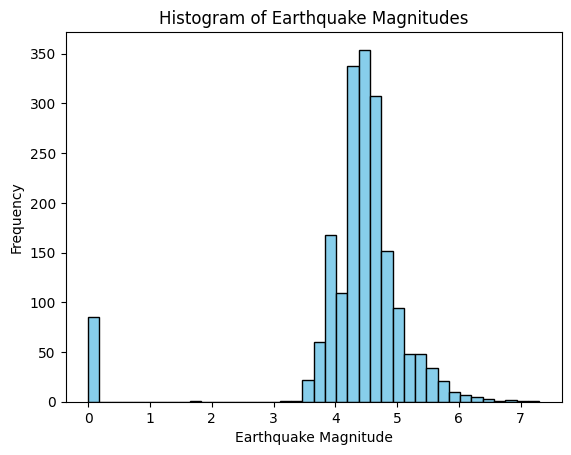

In [ ]:
magnitude_column = data_n['mag']
# Create a histogram
plt.hist(magnitude_column, bins=40, color='skyblue', edgecolor='black')
# Add labels and title
plt.xlabel('Earthquake Magnitude')
plt.ylabel('Frequency')
plt.title('Histogram of Earthquake Magnitudes')
# Show the plot
plt.show()

**Resample Data**

In [ ]:
# Instantiate SMOTE                  # function make balace
smote = SMOTE(random_state=42)

# Apply SMOTE to the data
X_balanced, y_balanced = smote.fit_resample(X, y)

# Extracting y variables for latitude and longitude
y_lat = X_balanced['latitude']
y_long = X_balanced['longitude']

# Dropping columns from X
X_balanced = X_balanced.drop(['longitude', 'latitude'], axis=1)

X_balanced.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2892 entries, 0 to 2891
Data columns (total 19 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   time             2892 non-null   float64
 1   depth            2892 non-null   float64
 2   magType          2892 non-null   float64
 3   nst              2892 non-null   float64
 4   gap              2892 non-null   float64
 5   dmin             2892 non-null   float64
 6   rms              2892 non-null   float64
 7   net              2892 non-null   float64
 8   id               2892 non-null   float64
 9   updated          2892 non-null   float64
 10  place            2892 non-null   float64
 11  type             2892 non-null   float64
 12  horizontalError  2892 non-null   float64
 13  depthError       2892 non-null   float64
 14  magError         2892 non-null   float64
 15  magNst           2892 non-null   float64
 16  status           2892 non-null   float64
 17  locationSource

In [ ]:
# Apply SMOTE to the data
X_balanced, y_balanced = smote.fit_resample(X, y)

In [ ]:
y_balanced

0       0
1       0
2       0
3       0
4       0
       ..
2887    1
2888    1
2889    1
2890    1
2891    1
Name: magnitude, Length: 2892, dtype: int64

Feature Selection

In [ ]:
X_balanced = X_balanced.drop(['updated', 'id', 'nst','nst','magSource', 'net', 'locationSource'], axis=1)
# Fit and transform the imputer on your data
X_imputed = imputer.fit_transform(X_balanced)

# Now use SelectKBest on the imputed data
selector_magnitudo = SelectKBest(score_func=f_regression, k=9)
X_new_magnitudo = selector_magnitudo.fit_transform(X_balanced,y_balanced )


# Get selected feature indices for 'magnitudo'
selected_indices_magnitudo = selector_magnitudo.get_support(indices=True)

# Extract selected features for 'magnitudo' only
selected_features_magnitudo = X_balanced.columns[selected_indices_magnitudo]
print("Selected features for magnitudo:", selected_features_magnitudo)
x=X_balanced
X_n = X_balanced[selected_features_magnitudo]


Selected features for magnitudo: Index(['time', 'depth', 'magType', 'gap', 'rms', 'horizontalError',
       'depthError', 'magError', 'magNst'],
      dtype='object')


In [ ]:
X_balanced

,time,latitude,longitude,depth,magType,gap,dmin,rms,place,type,horizontalError,depthError,magError,magNst,status
0,1.000000,0.616404,0.841192,0.047141,0.0,0.338180,0.612000,1.060000,0.458155,0.0,4.200000,0.033389,0.511000,1.000000,0.0
1,0.999466,0.664116,0.818582,0.274674,0.0,0.256005,0.414000,0.600000,0.441662,0.0,6.800000,0.131886,0.169000,10.000000,0.0
2,0.998932,0.756564,0.967095,0.552909,0.0,0.338180,0.991000,1.020000,0.021381,0.0,5.600000,0.131886,0.148000,13.000000,0.0
3,0.998397,0.201988,0.874269,0.330241,0.0,0.786979,2.673000,0.870000,0.761759,0.0,11.100000,0.130217,0.262000,4.000000,0.0
4,0.997863,0.553698,0.793818,0.265196,0.0,0.167509,0.451000,0.770000,0.202810,0.0,5.800000,0.101836,0.061000,80.000000,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2887,0.120444,0.701302,0.934297,0.360643,0.0,0.328776,1.905306,1.270970,0.982054,0.0,7.577316,0.112206,0.151140,8.782274,0.0
2888,0.000774,0.852611,0.494575,0.086044,3.0,0.328776,1.905306,0.877882,0.293209,0.0,7.577316,0.417362,0.417284,17.098582,0.0
2889,0.253113,0.677955,0.802379,0.315174,3.0,0.328776,1.905306,1.000000,0.453315,0.0,7.577316,0.165925,0.151140,17.098582,0.0
2890,0.083344,0.486539,0.645773,0.223934,0.0,0.328776,1.905306,0.877882,0.107342,0.0,7.577316,0.165925,0.151140,17.098582,0.0


Train & Test

In [ ]:
pip install scikit-plot

In [ ]:
# Splitting data into training and testing sets (adjust test_size and random_state as needed)
X_train, X_test, y_mag_train, y_mag_test, y_lat_train, y_lat_test, y_long_train, y_long_test = train_test_split(
    X_n, y_balanced, y_lat, y_long, test_size=0.2, random_state=42
)


In [ ]:
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.fit_transform(X_test)


Multi Output model

In [ ]:
input_layer = Input(shape=(X_train_imputed.shape[1],))
x = Dense(1024, activation='relu')(input_layer)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)
x = Dense(512, activation='relu', kernel_regularizer=l2(0.01))(x)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)
x = Dense(512, activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)
x = Dense(64, activation='relu', kernel_regularizer=l2(0.01))(x)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)
x = Dense(64, activation='relu')(x)
x = BatchNormalization()(x)


# Output layers for floating-point values (longitude)
float_long_output_layer = Dense(1, activation='linear', name='float_long_output')(x)

# Output layers for floating-point values (latitude)
float_lat_output_layer = Dense(1, activation='linear', name='float_lat_output')(x)

# Output layer for binary classification (magnitude)
binary_output_layer = Dense(1, activation='sigmoid', name='binary_output')(x)

# Define the model
model = Model(inputs=input_layer, outputs=[float_long_output_layer, float_lat_output_layer, binary_output_layer])

# Compile the model with appropriate loss functions for each output
model.compile(optimizer='adam',
              loss={'float_long_output': 'mean_squared_error', 'float_lat_output': 'mean_squared_error', 'binary_output': 'binary_crossentropy'},
              metrics={'float_long_output': 'mae', 'float_lat_output': 'mae', 'binary_output': 'accuracy'})

# Train the model
model.fit(X_train, {'float_long_output': y_long_train, 'float_lat_output': y_lat_train, 'binary_output': y_mag_train},
          epochs=50, batch_size=32,
          validation_data=(X_test, {'float_long_output': y_long_test, 'float_lat_output': y_lat_test, 'binary_output': y_mag_test}))

# Evaluate the model on the test set
eval_results = model.evaluate(X_test, {'float_long_output': y_long_test, 'float_lat_output': y_lat_test, 'binary_output': y_mag_test})

# Extract the evaluation metrics
mse_long, mae_long, mag_loss, mse_lat, mae_lat, binary_accuracy = eval_results[1], eval_results[2], eval_results[3], eval_results[4], eval_results[4],eval_results[6]

# Print the results
print(f'Mean Squared Error (Longitude): {mse_long}')
print(f'Mean Absolute Error (Longitude): {mae_long}')
print(f'Mean Absolute Error (Latitude): {mae_lat}')
print(f'Mean Squared Error (Latitude): {mse_lat}')
print(f'Binary Magnitude loss: {mag_loss}')
print(f'Binary Classification Accuracy: {binary_accuracy}')


Epoch 1/50
73/73 [==============================] - 6s 32ms/step - loss: 9.0506 - float_long_output_loss: 0.9561 - float_lat_output_loss: 0.9683 - binary_output_loss: 0.6167 - float_long_output_mae: 0.7427 - float_lat_output_mae: 0.7416 - binary_output_accuracy: 0.6783 - val_loss: 7.1624 - val_float_long_output_loss: 0.2396 - val_float_lat_output_loss: 0.4406 - val_binary_output_loss: 0.6470 - val_float_long_output_mae: 0.4462 - val_float_lat_output_mae: 0.4734 - val_binary_output_accuracy: 0.7409
Epoch 2/50
73/73 [==============================] - 2s 32ms/step - loss: 6.5453 - float_long_output_loss: 0.2251 - float_lat_output_loss: 0.2732 - binary_output_loss: 0.5367 - float_long_output_mae: 0.3730 - float_lat_output_mae: 0.4109 - binary_output_accuracy: 0.7302 - val_loss: 5.8122 - val_float_long_output_loss: 0.0475 - val_float_lat_output_loss: 0.0672 - val_binary_output_loss: 0.5332 - val_float_long_output_mae: 0.1854 - val_float_lat_output_mae: 0.2138 - val_binary_output_accuracy: 0

LSTM

In [ ]:
X_train = X_train.values.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_test= X_test.values.reshape((X_test.shape[0], 1, X_test.shape[1]))

input_layer = Input(shape=(X_train.shape[1], X_train.shape[2]))
x = LSTM(1024, activation='relu', return_sequences=True)(input_layer)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)
x = LSTM(512, activation='relu', kernel_regularizer=l2(0.01), return_sequences=True)(x)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)
x = LSTM(512, activation='relu', return_sequences=True)(x)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)
x = LSTM(64, activation='relu', kernel_regularizer=l2(0.01))(x)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)
x = Dense(64, activation='relu')(x)
x = BatchNormalization()(x)


# Output layers for floating-point values (longitude)
float_long_output_layer = Dense(1, activation='linear', name='float_long_output')(x)

# Output layers for floating-point values (latitude)
float_lat_output_layer = Dense(1, activation='linear', name='float_lat_output')(x)

# Output layer for binary classification (magnitude)
binary_output_layer = Dense(1, activation='sigmoid', name='binary_output')(x)

# Define the model
model = Model(inputs=input_layer, outputs=[float_long_output_layer, float_lat_output_layer, binary_output_layer])

# Compile the model with appropriate loss functions for each output
model.compile(optimizer='adam',
              loss={'float_long_output': 'mean_squared_error', 'float_lat_output': 'mean_squared_error', 'binary_output': 'binary_crossentropy'},
              metrics={'float_long_output': 'mae', 'float_lat_output': 'mae', 'binary_output': 'accuracy'})

# Train the model
model.fit(X_train, {'float_long_output': y_long_train, 'float_lat_output': y_lat_train, 'binary_output': y_mag_train},
          epochs=50, batch_size=32,
          validation_data=(X_test, {'float_long_output': y_long_test, 'float_lat_output': y_lat_test, 'binary_output': y_mag_test}))

# Evaluate the model on the test set
eval_results = model.evaluate(X_test, {'float_long_output': y_long_test, 'float_lat_output': y_lat_test, 'binary_output': y_mag_test})

# Extract the evaluation metrics
mse_long, mae_long, mag_loss, mse_lat, mae_lat, binary_accuracy = eval_results[1], eval_results[2], eval_results[3], eval_results[4], eval_results[4],eval_results[6]

# Print the results
print(f'Mean Squared Error (Longitude): {mse_long}')
print(f'Mean Absolute Error (Longitude): {mae_long}')
print(f'Mean Absolute Error (Latitude): {mae_lat}')
print(f'Mean Squared Error (Latitude): {mse_lat}')
print(f'Binary Magnitude loss: {mag_loss}')
print(f'Binary Classification Accuracy: {binary_accuracy}')


Epoch 1/50
73/73 [==============================] - 26s 250ms/step - loss: 12.8844 - float_long_output_loss: 0.7919 - float_lat_output_loss: 0.7894 - binary_output_loss: 0.6085 - float_long_output_mae: 0.6973 - float_lat_output_mae: 0.6726 - binary_output_accuracy: 0.6900 - val_loss: 9.3139 - val_float_long_output_loss: 0.1356 - val_float_lat_output_loss: 0.1258 - val_binary_output_loss: 0.6925 - val_float_long_output_mae: 0.3403 - val_float_lat_output_mae: 0.3154 - val_binary_output_accuracy: 0.4819
Epoch 2/50
73/73 [==============================] - 17s 234ms/step - loss: 8.2786 - float_long_output_loss: 0.1900 - float_lat_output_loss: 0.2094 - binary_output_loss: 0.5177 - float_long_output_mae: 0.3469 - float_lat_output_mae: 0.3526 - binary_output_accuracy: 0.7449 - val_loss: 7.1995 - val_float_long_output_loss: 0.0375 - val_float_lat_output_loss: 0.0544 - val_binary_output_loss: 0.6999 - val_float_long_output_mae: 0.1562 - val_float_lat_output_mae: 0.1944 - val_binary_output_accura

Epoch 1/10
73/73 [==============================] - 3s 12ms/step - loss: 0.5873 - accuracy: 0.7298 - val_loss: 0.5209 - val_accuracy: 0.7599
Epoch 2/10
73/73 [==============================] - 0s 4ms/step - loss: 0.5204 - accuracy: 0.7536 - val_loss: 0.4736 - val_accuracy: 0.7893
Epoch 3/10
73/73 [==============================] - 0s 6ms/step - loss: 0.4842 - accuracy: 0.7670 - val_loss: 0.4402 - val_accuracy: 0.8117
Epoch 4/10
73/73 [==============================] - 0s 6ms/step - loss: 0.4481 - accuracy: 0.7920 - val_loss: 0.4246 - val_accuracy: 0.7893
Epoch 5/10
73/73 [==============================] - 0s 7ms/step - loss: 0.4151 - accuracy: 0.8063 - val_loss: 0.3910 - val_accuracy: 0.8221
Epoch 6/10
73/73 [==============================] - 0s 6ms/step - loss: 0.3873 - accuracy: 0.8201 - val_loss: 0.3764 - val_accuracy: 0.8497
Epoch 7/10
73/73 [==============================] - 1s 7ms/step - loss: 0.3666 - accuracy: 0.8344 - val_loss: 0.3643 - val_accuracy: 0.8273
Epoch 8/10
73/73 [=

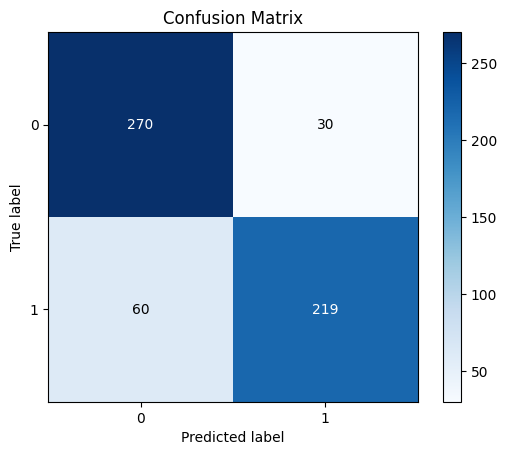

In [ ]:
# Convert Pandas Series to NumPy arrays and reshape
y_mag_train = np.array(y_mag_train).reshape(-1, 1)
y_mag_test = np.array(y_mag_test).reshape(-1, 1)

# Create a simple LSTM model
model = Sequential()
model.add(LSTM(50, input_shape=(X_train.shape[1], X_train.shape[2])))
model.add(Dense(1, activation='sigmoid'))
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(X_train, y_mag_train, epochs=10, batch_size=32, validation_data=(X_test, y_mag_test))

# Predictions
y_pred = model.predict(X_test)
y_pred_binary = (y_pred > 0.5).astype(int)  # Convert probabilities to binary predictions

# Confusion Matrix
cm = confusion_matrix(y_mag_test, y_pred_binary)
print("Confusion Matrix:")
print(cm)

# Plot Confusion Matrix
plot_confusion_matrix(y_mag_test, y_pred_binary)
plt.title('Confusion Matrix')
plt.show()

19/19 [==============================] - 0s 2ms/step


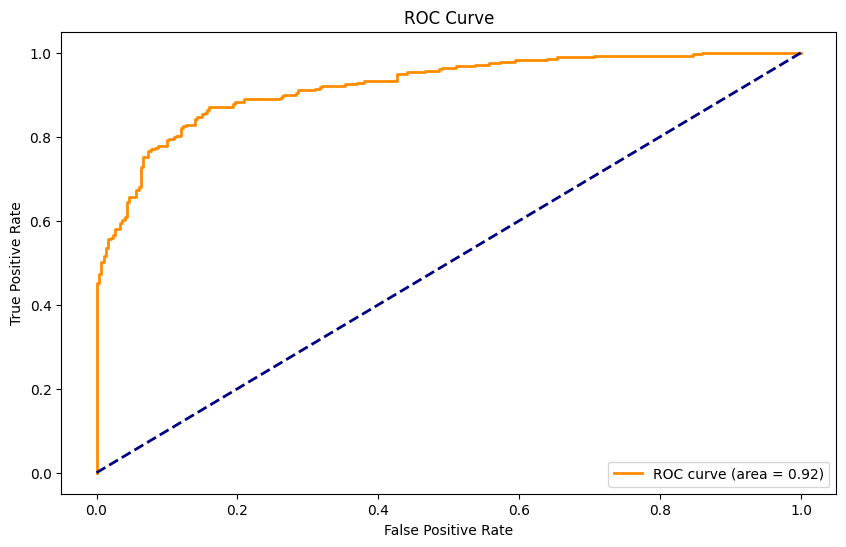

In [ ]:
y_mag_pred = model.predict(X_test)
# Assuming y_test contains true labels (binary) and y_pred contains predicted probabilities
fpr, tpr, thresholds = roc_curve(y_mag_test, y_mag_pred)
roc_auc = auc(fpr, tpr)
# Plot the ROC curve
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.show()

predict magintude(float)

linear Regrission

In [ ]:
Y= data_n['mag']                            #  drop mag and magnitude
x= data_n.drop(['mag', 'magnitude'], axis=1)
# Create a SimpleImputer instance
imputer = SimpleImputer(strategy='mean') # null replace by mean missing values
# Fit the imputer on your data and transform it
impute = imputer.fit_transform(x)
x = pd.DataFrame(impute, columns=x.columns)

In [ ]:
#splitting
X_train, X_test, y_train, y_test = train_test_split(
    x, Y, test_size=0.2, random_state=42
)

In [ ]:
# Create a SimpleImputer instance
imputer = SimpleImputer(strategy='mean')

# Fit and transform the imputer on your training data
X_train_imputed = imputer.fit_transform(X_train)

# Transform the imputer on your testing data
X_test_imputed = imputer.transform(X_test)

# Now use LinearRegression on the imputed data
model = LinearRegression().fit(X_train_imputed, y_train)
y_pred = model.predict(X_test_imputed)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'Mean Squared Error: {mse}')
print(f'R-squared (Accuracy): {r2}')


Mean Squared Error: 0.23587354121696638
R-squared (Accuracy): 0.7517107887775769


Multi layer NN (linear)

In [ ]:
# Model architecture
input_layer = Input(shape=(X_train_imputed.shape[1],))
x = Dense(1024, activation='relu')(input_layer)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)
x = Dense(512, activation='relu', kernel_regularizer=l2(0.01))(x)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)
x = Dense(512, activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)
x = Dense(64, activation='relu', kernel_regularizer=l2(0.01))(x)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)
x = Dense(64, activation='relu')(x)
x = BatchNormalization()(x)

# Output layers for floating-point values (magnitude regression)
mag_output_layer = Dense(1, activation='linear', name='mag')(x)  # Changed to one output neuron

model = Model(inputs=input_layer, outputs=[mag_output_layer])

# Compile the model with appropriate loss functions for each output
model.compile(optimizer='adam',
              loss={'mag': 'mean_squared_error'},
              metrics={'mag': 'mse'})

# Train the model
model.fit(X_train_imputed, {'mag': y_train}, epochs=10, batch_size=20, validation_data=(X_test_imputed, {'mag': y_test}))


Epoch 1/10
75/75 [==============================] - 6s 32ms/step - loss: 23.6052 - mse: 16.9995 - val_loss: 16.0973 - val_mse: 10.1004
Epoch 2/10
75/75 [==============================] - 2s 26ms/step - loss: 15.2271 - mse: 9.5505 - val_loss: 11.0048 - val_mse: 5.6611
Epoch 3/10
75/75 [==============================] - 1s 19ms/step - loss: 8.2704 - mse: 3.2483 - val_loss: 5.5862 - val_mse: 0.8940
Epoch 4/10
75/75 [==============================] - 1s 17ms/step - loss: 5.5858 - mse: 1.1991 - val_loss: 4.8660 - val_mse: 0.7877
Epoch 5/10
75/75 [==============================] - 1s 18ms/step - loss: 4.6713 - mse: 0.8819 - val_loss: 4.1476 - val_mse: 0.6460
Epoch 6/10
75/75 [==============================] - 1s 17ms/step - loss: 3.9484 - mse: 0.7059 - val_loss: 3.5420 - val_mse: 0.5566
Epoch 7/10
75/75 [==============================] - 1s 17ms/step - loss: 3.4500 - mse: 0.6842 - val_loss: 3.0700 - val_mse: 0.5135
Epoch 8/10
75/75 [==============================] - 1s 17ms/step - loss: 2.97

Multi layer NN (non linear)

In [ ]:
# Check for NaN or infinite values in input data
if np.isnan(np.sum(X_train.values)) or np.isnan(np.sum(X_test.values)) or not np.isfinite(np.sum(X_train.values)) or not np.isfinite(np.sum(X_test.values)):
    # Impute missing values if necessary
    imputer = SimpleImputer(strategy='mean')
    X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns)
    X_test = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns)

    # Check again after imputation
    if np.isnan(np.sum(X_train.values)) or np.isnan(np.sum(X_test.values)) or not np.isfinite(np.sum(X_train.values)) or not np.isfinite(np.sum(X_test.values)):
        raise ValueError("Input data still contains NaN or infinite values after imputation.")

# Check for NaN or infinite values in labels
if np.isnan(np.sum(y_train)) or np.isnan(np.sum(y_test)) or not np.isfinite(np.sum(y_train)) or not np.isfinite(np.sum(y_test)):
    raise ValueError("Labels contain NaN or infinite values.")

# Normalize your input data
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

x = Dense(1024, activation='relu')(input_layer)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)

x= Dense(units = 5, activation = 'sigmoid')(x)
x= Dropout(0.2)(x)

x = Dense(512, activation='relu', kernel_regularizer=l2(0.01))(x)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)
x = Dense(512, activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)
x = Dense(64, activation='relu', kernel_regularizer=l2(0.01))(x)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)
x = Dense(64, activation='relu')(x)
x = BatchNormalization()(x)

mag_output_layer = Dense(1, activation='linear', name='mag')(x)

model = Model(inputs=input_layer, outputs=[mag_output_layer])

# Compile the model with appropriate loss functions for each output
model.compile(optimizer='adam',
              loss={'mag': 'mean_squared_error'},
              metrics={'mag': 'mse'})

# Train the model
history = model.fit(X_train_scaled, {'mag': y_train}, epochs=10, batch_size=20, validation_data=(X_test_scaled, {'mag': y_test}))

# Print the training history
print("Training History:")
print(history.history)


Epoch 1/10
75/75 [==============================] - 5s 16ms/step - loss: 18.1189 - mse: 16.8818 - val_loss: 16.1911 - val_mse: 14.9680
Epoch 2/10
75/75 [==============================] - 1s 11ms/step - loss: 10.3632 - mse: 9.1596 - val_loss: 6.8433 - val_mse: 5.6603
Epoch 3/10
75/75 [==============================] - 1s 11ms/step - loss: 4.4563 - mse: 3.2929 - val_loss: 2.3845 - val_mse: 1.2419
Epoch 4/10
75/75 [==============================] - 1s 11ms/step - loss: 2.3659 - mse: 1.2458 - val_loss: 1.9811 - val_mse: 0.8842
Epoch 5/10
75/75 [==============================] - 1s 11ms/step - loss: 2.0975 - mse: 1.0244 - val_loss: 1.9519 - val_mse: 0.9038
Epoch 6/10
75/75 [==============================] - 1s 12ms/step - loss: 1.8479 - mse: 0.8246 - val_loss: 1.7906 - val_mse: 0.7937
Epoch 7/10
75/75 [==============================] - 1s 10ms/step - loss: 1.5247 - mse: 0.5554 - val_loss: 1.6350 - val_mse: 0.6943
Epoch 8/10
75/75 [==============================] - 1s 11ms/step - loss: 1.554

In [ ]:
# Predictions
regression_predictions = model.predict(X_test_scaled)

# Print some predictions for analysis
print("Some predictions:")
for i in range(5):
    print(f"Prediction: {regression_predictions[i][0]}, True Value: {y_test.iloc[i]}")


# Evaluate regression performance
regression_r2 = r2_score(y_test, regression_predictions)
print(f'R2 score: {regression_r2}')

regression_mse = mean_squared_error(y_test, regression_predictions)
print(f'Mean Squared Error: {regression_mse:.3f}')


12/12 [==============================] - 0s 5ms/step
Some predictions:
Prediction: 4.283516883850098, True Value: 5.0
Prediction: 4.174908638000488, True Value: 4.6
Prediction: 4.816539287567139, True Value: 5.2
Prediction: 4.238704204559326, True Value: 4.4
Prediction: 4.777915954589844, True Value: 5.7
R2 score: 0.8164444559049934
Mean Squared Error: 0.174


Ensample NN

In [ ]:
# Predictions
regression_predictions = model.predict(X_test_scaled)

# Print some predictions for analysis
print("Some predictions:")
for i in range(5):
    print(f"Prediction: {regression_predictions[i][0]}, True Value: {y_test.iloc[i]}")


# Evaluate regression performance
regression_r2 = r2_score(y_test, regression_predictions)
print(f'R2 score: {regression_r2}')

regression_mse = mean_squared_error(y_test, regression_predictions)
print(f'Mean Squared Error: {regression_mse:.3f}')


12/12 [==============================] - 0s 5ms/step
Some predictions:
Prediction: 4.283516883850098, True Value: 5.0
Prediction: 4.174908638000488, True Value: 4.6
Prediction: 4.816539287567139, True Value: 5.2
Prediction: 4.238704204559326, True Value: 4.4
Prediction: 4.777915954589844, True Value: 5.7
R2 score: 0.8164444559049934
Mean Squared Error: 0.174
